# LinearAlgebra

In [67]:
import numpy as np
from numpy import linalg
import sympy 
import matplotlib.pyplot as plt 
import pandas as pd

## Dot Product similarity

In [3]:
a = np.array([5,4,1])
b = np.array([4,5,2])
c = np.array([1,2,5])

dot_prd_a_b = np.dot(a,b)
the_cos_a_b = dot_prd_a_b/(np.linalg.norm(a)*np.linalg.norm(b))
angle_a_b   = np.degrees(np.arccos(the_cos_a_b))


dot_prd_a_c = np.dot(a,c)
the_cos_a_c = dot_prd_a_c/(np.linalg.norm(a)*np.linalg.norm(c))
angle_a_c   = np.degrees(np.arccos(the_cos_a_c))

print(angle_a_b,angle_a_c,sep="\n")

14.96321743330715
59.52964053402026


##  solution system equations 

### 1 set up equation matrix and augmented results

In [34]:
coffee=  np.array([[300,100],
                   [100,200]] )
result=  np.array([11000, 8000])

### 2 onelinear solution using linalg.solve(matrix_v , matrix_augment_result)

In [36]:
linalg.solve(coffee, result)

array([28., 26.])

In [37]:
sympy.sympify(linalg.solve(coffee, result))

[28.0, 26.0]

### 2 step by setp solution - inv + matmul

#### 2.1 inv

In [28]:
cof_inv=linalg.inv(coffee)
cof_inv

array([[ 0.004, -0.002],
       [-0.002,  0.006]])

In [29]:
sympy.sympify(cof_inv)

[[0.004, -0.002], [-0.002, 0.006]]

#### 2.2 matmul

##### 2.2.1 identity matrix

In [38]:
cof_iden=linalg.matmul(coffee,cof_inv)
cof_iden

array([[1., 0.],
       [0., 1.]])

In [31]:
sympy.sympify(cof_iden)

[[1.0, 0.0], [0.0, 1.0]]

In [18]:
sympy.sympify( coffee  )

[[300, 100], [100, 200]]

In [32]:
linalg.matmul(linalg.inv(coffee), coffee)

array([[1., 0.],
       [0., 1.]])

##### 2.2.2 solution matrix

In [33]:
linalg.matmul(linalg.inv(coffee), result)

array([28., 26.])

##  Roatation 

In [79]:
p_m=np.array([ [1,1],   # x coordinate first columns
               [3,1],
               [2,2] ]) # y coordinate

r_m=np.array([ [0,-1],
               [1,0] ] )

R_M=p_m @ r_m
df0=pd.DataFrame(data=(p_m))
df1=pd.DataFrame(data=(R_M))

df=pd.concat((df0,df1),axis=1)
df.columns=["x1","y1","x2","y2"]
df.index=np.arange(1,4)

,x1,y1,x2,y2
1,1,1,1,-1
2,3,1,1,-3
3,2,2,2,-2


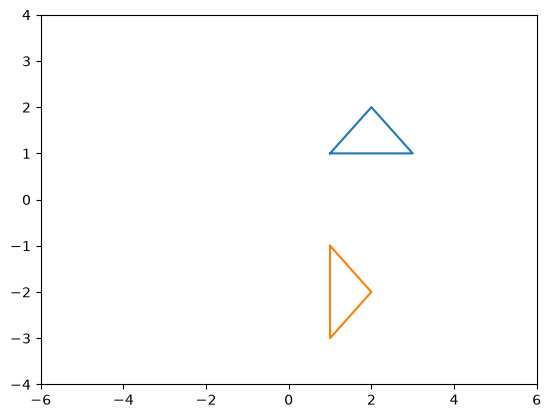

In [82]:
plt.ylim(-4,4)
plt.xlim(-6,6)
plt.plot( [1,3,2,1],   
               [1,1,2,1] )
plt.plot([1,1,2,1],
        [-1,-3,-2,-1])
plt.show()

##  scale determinant

<ul>
    <li> 1 area is perfectly preserved</li>
    <li> 2 doubles</li>
    <li> <0 flipped (orientation of the space)</li>
    <li> 0 the matrix has been squished into a line or a point |Name singular matrix , nonirreversable matrix|</li>
</ul>

In [107]:
#            x  y 
R_matrix=np.array([[0,-1],
            [1, 0]])
S_matrix=np.array([[2, 0],
            [0, 3]])
C_matrix=np.array([[1,2],
            [2,4]])

matrix_det=[]
matrix_lst=[R_matrix,S_matrix,C_matrix]
for i in range(len(matrix_lst)):
   matrix_det.append( int( linalg.det(matrix_lst[i])  )  )

matrix_det

[1, 6, 0]

In [108]:
matrix_original_sacle=np.array([[0,1],
                                [1,1]])
R_S=matrix_original_sacle @ R_matrix
S_S=matrix_original_sacle @ S_matrix
C_S=matrix_original_sacle @ C_matrix

print(matrix_original_sacle,R_S,S_S,C_S,sep="\n\n")

[[0 1]
 [1 1]]

[[ 1  0]
 [ 1 -1]]

[[0 3]
 [2 3]]

[[2 4]
 [3 6]]


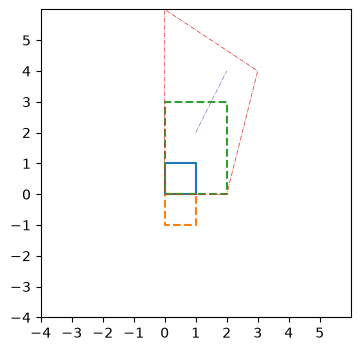

In [123]:
plt.figure(figsize=(4,4))
plt.xticks(np.arange(-4,6,1))
plt.yticks(np.arange(-4,6,1))
plt.xlim(-4,6)
plt.ylim(-4,6)
plt.plot([0,1,1,0,0],[0,0,1,1,0])
plt.plot([0,1,1,0,0],[0,0,-1,-1,0],ls="--")
plt.plot([0,2,2,0,0],[0,0,3,3,0],ls="--")
plt.plot([0,2,3,0,0],[0,0,4,6,0],ls="-.",lw=0.5)
plt.plot([1,2],[2,4],ls="-.",lw=0.5)
plt.show()

## matmul why

In [146]:
m_mat1 = np.array([[5,1],
                 [2,3]])
m_mat2 = np.array([[10,11],
                 [20,22]])
m_matm =linalg.matmul(mat1,mat2)


In [147]:
df1_products =pd.DataFrame(m_mat1,columns=["Flour","Sugar"],
                           index=["Cakes","Cookies"])
df2_supplier =pd.DataFrame(m_mat2,columns=["P","Q"],
                           index=["Flour","Sugar"])
df3_ResulstP =pd.DataFrame(m_matm,columns=["P","Q"],
                           index=["Cakes","Cookies"])


In [134]:
df1_products

,Flour,Sugar
Cakes,5,1
Cookies,2,3


In [135]:
df2_supplier

,P,Q
Flour,10,11
Sugar,20,22


In [136]:
df3_ResulstP

,P,Q
Cakes,70,77
Cookies,80,88


In [197]:
df_prd_sup=pd.DataFrame( data =[[5,1,"$\\downarrow$","Flour",10,11,"$\\rightarrow$","Cakes",70,77],
                               [2,3,"$\\downarrow$","Sugar",20,11,"$\\rightarrow$","Cookies",80,88]],
                         index=["Cakes","Cookies"],
                         columns=["Flour","Sugar","$\\rightarrow$","Ingredient","P","Q","$\\rightarrow$","Products","P","Q"])

df_prd_sup

,Flour,Sugar,$\rightarrow$,Ingredient,P,Q,$\rightarrow$,Products,P,Q
Cakes,5,1,$\downarrow$,Flour,10,11,$\rightarrow$,Cakes,70,77
Cookies,2,3,$\downarrow$,Sugar,20,11,$\rightarrow$,Cookies,80,88


In [216]:
df_prd_sup.style.set_table_styles([{ "selector" : "th.col0","props":"color:red;background-color:yellow;border:double indigo 2px"},
                                   { "selector" : "td.row0.col3","props":"color:red;background-color:yellow;border:double indigo 2px"},
                                   { "selector" : "th.col1","props":"color:blue;background-color:yellow;border:double indigo 2px"},
                                   { "selector" : "td.row1.col3","props":"color:blue;background-color:yellow;border:double indigo 2px"} ,  
                                   { "selector" : "td.row0.col0","props":"color:blue;background-color:cyan;border:double indigo 2px"}  ,
                                   { "selector" : "td.row0.col4","props":"color:blue;background-color:cyan;border:double indigo 2px"}   ,
                                   { "selector" : "td.row0.col1","props":"color:brown;background-color:cyan;border:double indigo 2px"}  ,
                                   { "selector" : "td.row1.col4","props":"color:brown;background-color:cyan;border:double indigo 2px"}  , 
                                   { "selector" : "td.row0.col8","props":"color:black;background-color:cyan;border:double indigo 2px"}  
                                  ])

,Flour,Sugar,$\rightarrow$,Ingredient,P,Q,$\rightarrow$,Products,P,Q
Cakes,5,1,$\downarrow$,Flour,10,11,$\rightarrow$,Cakes,70,77
Cookies,2,3,$\downarrow$,Sugar,20,11,$\rightarrow$,Cookies,80,88
